--- Data Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18524 entries, 0 to 18523
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         18524 non-null  int64  
 1   Time_spent_Alone           17334 non-null  float64
 2   Stage_fear                 16631 non-null  object 
 3   Social_event_attendance    17344 non-null  float64
 4   Going_outside              17058 non-null  float64
 5   Drained_after_socializing  17375 non-null  object 
 6   Friends_circle_size        17470 non-null  float64
 7   Post_frequency             17260 non-null  float64
 8   Personality                18524 non-null  object 
dtypes: float64(5), int64(1), object(3)
memory usage: 1.3+ MB
None

--- Summary Statistics ---
Mean of Time_spent_Alone: 3.1377639321564557
Median of Time_spent_Alone: 2.0
Mode of Stage_fear: No
Standard Deviation: 3.0036996891220005
Variance: 9.022211822

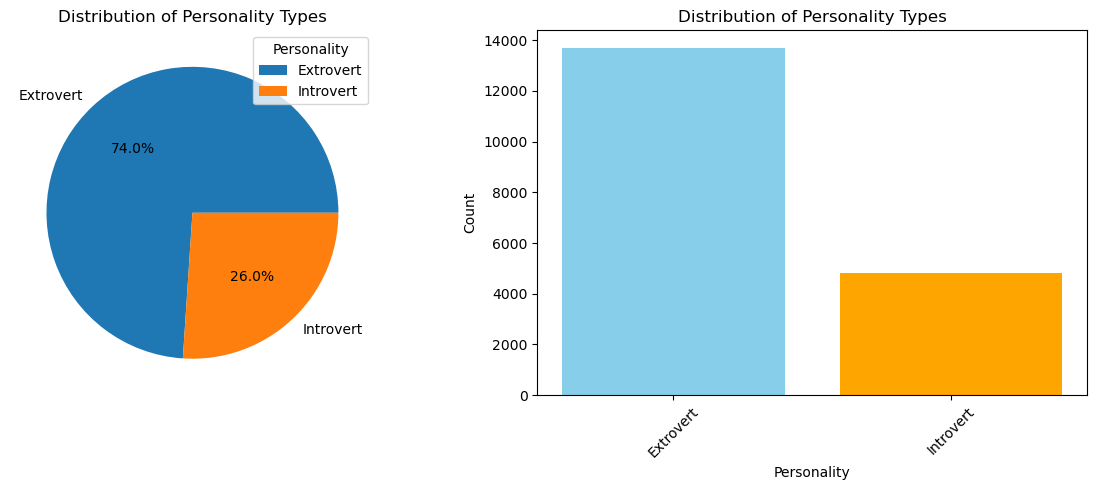

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics
import warnings

warnings.filterwarnings("ignore")

# Load and Inspect Data
df = pd.read_csv("playground-series-s5e7train.csv")
print("--- Data Summary ---")
print(df.info())

# Data Cleaning
no_null_df = df.dropna(how="any")
df.drop_duplicates(inplace=True)

# Statistical Analysis
ts_alone = df['Time_spent_Alone'].dropna()
stage_fear = df['Stage_fear'].dropna()

print("\n--- Summary Statistics ---")
print(f"Mean of Time_spent_Alone: {np.mean(ts_alone)}")
print(f"Median of Time_spent_Alone: {np.median(ts_alone)}")
print(f"Mode of Stage_fear: {statistics.mode(stage_fear)}")
print(f"Standard Deviation: {np.std(ts_alone)}")
print(f"Variance: {np.var(ts_alone)}")

# Pivot Table
pivot = df.pivot_table(
    values='Time_spent_Alone',
    index='Personality',
    columns='Going_outside',
    aggfunc='mean'
)
print("\n--- Pivot Table ---")
print(pivot)

# Data Visualization
p_counts = df['Personality'].value_counts()

plt.figure(figsize=(12, 5))

# Pie Chart
plt.subplot(1, 2, 1)
plt.pie(
    p_counts,
    labels=p_counts.index,
    autopct='%1.1f%%'
)
plt.title('Distribution of Personality Types')
plt.legend(p_counts.index, title="Personality", loc="best")

# Bar Chart
plt.subplot(1, 2, 2)
plt.bar(
    p_counts.index,
    p_counts.values,
    color=['skyblue', 'orange']
)
plt.title('Distribution of Personality Types')
plt.xlabel('Personality')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
